# Predicting Used-Car Resale Prices (CarDekho, India)
**Course:** Introduction to Data Science  |  **Language:** Python  |  **Random seed:** 42 everywhere

**Core question.** *Given a used car's basic listing details (age, kilometres driven, fuel, transmission, owner count, engine specs, brand), how accurately can we predict its resale price in INR — and which factors drive that price most?*

**Secondary question.** *How does predicted price fall with car age, and does the pattern differ across brands / segments (budget, mid-range, luxury)?*

How this notebook maps to the grading rubric: §1 Problem & data → §2 Data preparation → §3 EDA → §4 Modelling → §5 Evaluation & error analysis → §6 Interpretation (SHAP) → §7 Secondary analysis → §8 Limitations & next steps → §9 Saving the model for the Tkinter frontend.

## 1. Problem & data

**Why this problem is worth solving.** A used-car price is not obvious: a 10-year-old diesel hatchback and a 10-year-old petrol luxury sedan depreciate very differently. A trustworthy price estimator helps buyers avoid overpaying and sellers avoid underpricing. It is **non-trivial** (prices span ₹30,000 to ₹1 crore, many interacting factors) and **measurable** (we have the real asking price, so we can compute prediction error in rupees and in %).

**Task type.** Supervised *regression*. Target = `selling_price` (INR).

**Dataset & justification.**
- **Source:** *Vehicle dataset from CarDekho* (file `Car details v3.csv`), uploaded to Kaggle by Nehal Birla — <https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho>. Listings scraped from CarDekho, an Indian used-car marketplace.
- **Size:** 8,128 rows × 13 columns (about 6,900 after removing duplicates, see §2) — big enough to train tree-based models and hold out a proper test set, small enough to run on a laptop in minutes.
- **Relevance:** it contains exactly the variables a buyer sees on a listing (year, km, fuel, transmission, owner, engine, power, mileage, seats), so the model is realistic and it can later power a desktop app where a user types those same fields.
- **Success criterion (defined before modelling):** beat a naive "always predict the median price" baseline by a wide margin, with a typical error (MAPE) comfortably below what the baseline achieves, and R² well above 0 on data the model has never seen.

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, shap

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV, cross_val_score
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             mean_absolute_percentage_error, make_scorer)
from xgboost import XGBRegressor

import car_features as cf
from car_features import RAW_FEATURES, NUM_COLS, CAT_COLS, RANDOM_STATE, REFERENCE_YEAR

from matplotlib.ticker import FuncFormatter, NullFormatter
def fix_logs():
    # show plain numbers (2, 5, 10, 20) instead of 10^x on log axes
    for ax in plt.gcf().axes:
        for axis, sc in ((ax.xaxis, ax.get_xscale()), (ax.yaxis, ax.get_yscale())):
            if sc == "log":
                axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}")); axis.set_minor_formatter(NullFormatter())

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
for d in ["figures", "results"]:
    os.makedirs(d, exist_ok=True)
print("Seed:", RANDOM_STATE, "| reference year for car age:", REFERENCE_YEAR)

Seed: 42 | reference year for car age: 2026


In [2]:
raw = pd.read_csv("data/Car_details_v3.csv")
print("Raw shape:", raw.shape)
display(raw.head())
print(raw.dtypes.to_string())
print("\nMissing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0].to_string())
print("\nExact duplicate rows:", raw.duplicated().sum())

Raw shape: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage              str
engine               str
max_power            str
torque               str
seats            float64

Missing values per column:
mileage      221
engine       221
max_power    215
torque       222
seats        221

Exact duplicate rows: 1202


## 2. Data preparation (every decision has a reason)

| # | Issue found | Decision | Why |
|---|---|---|---|
| 1 | `mileage`, `engine`, `max_power` are text ("23.4 kmpl", "1248 CC", "74 bhp") | Extract the number with a regex into numeric columns | Models need numbers; the unit is constant within each column (except mileage, see #2) |
| 2 | `mileage` mixes **kmpl** (petrol/diesel) and **km/kg** (CNG/LPG) | Keep the number, rely on `fuel` to tell the model which unit applies | Only ~1% of rows are km/kg; converting would need assumptions about fuel density |
| 3 | `max_power` = 0 (6 rows) and `mileage` = 0 (17 rows, counted before de-duplication) | Treat as missing (NaN) | A real car cannot have 0 bhp or 0 kmpl — these are placeholders, not measurements |
| 4 | `torque` is a mess ("190Nm@ 2000rpm", "22.4 kgm at 1750-2750rpm", "12.7@ 2,700(kgm@ rpm)") with two different units and rpm ranges | **Drop** the column | Parsing it reliably would need unit conversion + range handling, and it is largely redundant with `engine` and `max_power` |
| 5 | **Exact duplicate rows** (~15% of the file!) | Remove them **before** splitting | If a duplicate lands in train and its twin in test, the model is graded on cars it has already memorised — a classic data leak that inflates scores |
| 6 | Impossible `km_driven` values (2.36 M km, 1.5 M km on 10-year-old cars; 1 km on a 2011 car) | Remove rows with km ≥ 1,000,000 or km < 100 | Physically implausible (>100,000 km/year) — almost surely typos |
| 7 | `owner` has a 5-row "Test Drive Car" level | Merge into "First Owner" | 5 rows is too few to learn from; a demo car has no previous private owner |
| 8 | `name` has the brand as its first word; model/variant strings are too fine-grained | Extract `brand` (special-case "Land Rover") | Brand is the main driver of price tier; ~2,000 unique variant strings would just overfit |
| 9 | Missing `mileage/engine/max_power/seats` (~2.7%) | **Keep the rows**; impute with the median *inside the Pipeline* | Dropping loses data; imputing before the split would leak test-set statistics into training |
| 10 | Very expensive cars (up to ₹1 crore) | **Keep** them; model log(price) | They are genuine luxury listings, not errors. Log-transform tames the skew |

In [3]:
df = raw.copy()
log = []   # cleaning log, saved for the report
log.append(("raw rows", len(df)))

# 1) parse text units -> numbers
for c in ["mileage", "engine", "max_power"]:
    df[c] = df[c].apply(cf.parse_number)
print("mileage unit by fuel (raw):")
print(pd.crosstab(raw["fuel"], raw["mileage"].str.extract(r"([a-zA-Z/]+)$")[0].fillna("missing")))

# 3) max_power == 0 and mileage == 0 are placeholders, not real values
for c in ["max_power", "mileage"]:
    n_zero = int((df[c] == 0).sum())
    df.loc[df[c] == 0, c] = np.nan
    log.append((f"{c}=0 set to NaN", n_zero))

# 4) drop torque (inconsistent units)
df = df.drop(columns=["torque"])

# 5) duplicates
n_dup = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
log.append(("exact duplicates removed", n_dup))

# 6) impossible odometer readings
bad_km = (df["km_driven"] >= 1_000_000) | (df["km_driven"] < 100)
print("\nRemoved implausible km_driven rows:")
display(df.loc[bad_km, ["name", "year", "km_driven", "selling_price"]])
log.append(("implausible km_driven removed", int(bad_km.sum())))
df = df.loc[~bad_km].reset_index(drop=True)

# 7) merge tiny owner category
n_td = int((df["owner"] == "Test Drive Car").sum())
df["owner"] = df["owner"].replace({"Test Drive Car": "First Owner"})
log.append(("'Test Drive Car' merged into First Owner", n_td))

# 8) brand
df["brand"] = df["name"].apply(cf.extract_brand)

# sanity checks on remaining columns
assert (df["selling_price"] > 0).all() and df["year"].between(1980, 2026).all()
log.append(("final rows", len(df)))
print(pd.DataFrame(log, columns=["step", "rows"]).to_string(index=False))
pd.DataFrame(log, columns=["step", "rows"]).to_csv("results/cleaning_log.csv", index=False)

print("\nRows still missing at least one spec (kept, imputed later inside the pipeline):",
      int(df[["mileage", "engine", "max_power", "seats"]].isna().any(axis=1).sum()))
print("Brands:", df["brand"].nunique(), "| rarest:", df["brand"].value_counts().tail(6).to_dict())

mileage unit by fuel (raw):
0       km/kg  kmpl  missing
fuel                        
CNG        53     0        4
Diesel      0  4299      103
LPG        35     0        3
Petrol      0  3520      111

Removed implausible km_driven rows:


,name,year,km_driven,selling_price
1646,Mahindra XUV500 W6 2WD,2012,1500000,500000
3161,Hyundai i20 Asta 1.2,2007,2360457,550000
6737,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,1,209000


                                    step  rows
                                raw rows  8128
                  max_power=0 set to NaN     6
                    mileage=0 set to NaN    17
                exact duplicates removed  1202
           implausible km_driven removed     3
'Test Drive Car' merged into First Owner     5
                              final rows  6923

Rows still missing at least one spec (kept, imputed later inside the pipeline): 224
Brands: 32 | rarest: {'Daewoo': 3, 'Kia': 3, 'Lexus': 1, 'Ashok': 1, 'Opel': 1, 'Peugeot': 1}


### Train / validation / test split (80 / 10 / 10)

**Why three sets rather than two?** 
- **Train (80%)** — the only data models learn from. Hyper-parameter tuning uses 5-fold cross-validation *inside* this set.
- **Validation (10%)** — used once per model to **compare models and choose the winner**. 
- **Test (10%)** — touched **only at the very end**, for the final honest score. If I picked the model using test results, the test score would be optimistic (I'd have "trained on the test set" through my own choices).

I split **before any EDA or feature work**, stratifying on price deciles so each set has a similar mix of cheap and expensive cars (the price distribution is heavily skewed, so a purely random split could leave the test set short of luxury cars). `random_state=42`.

**No-leakage checklist:** (1) duplicates removed before the split; (2) all fitted preprocessing — median imputation, scaling, one-hot encoding — lives inside the sklearn `Pipeline`, so within every CV fold it is fitted on that fold's training part only; (3) the engineered features (age, km/year, brand tier) are *stateless formulas / a fixed lookup*, nothing is learned from the data; (4) brand tier is defined by market positioning, not by looking at prices.

In [4]:
FEATURES, TARGET = RAW_FEATURES, "selling_price"
strata = pd.qcut(df[TARGET], 10, labels=False)
train_idx, temp_idx = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=strata)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=RANDOM_STATE, stratify=strata.loc[temp_idx])

X_train, y_train = df.loc[train_idx, FEATURES], df.loc[train_idx, TARGET]
X_val,   y_val   = df.loc[val_idx, FEATURES],   df.loc[val_idx, TARGET]
X_test,  y_test  = df.loc[test_idx, FEATURES],  df.loc[test_idx, TARGET]
print(f"train={len(X_train)}  val={len(X_val)}  test={len(X_test)}")
print("median price (INR)  train/val/test:", int(y_train.median()), int(y_val.median()), int(y_test.median()))
assert len(set(train_idx) & set(test_idx)) == 0 and len(set(train_idx) & set(val_idx)) == 0

train=5538  val=692  test=693
median price (INR)  train/val/test: 400000 404999 400000


## 3. Exploratory data analysis (training set only)

Feature engineering used throughout (implemented once in `car_features.py` and reused by the model pipeline):
- **`age`** = 2026 − `year` (reference year 2026). Newer cars cost more; age is easier to interpret than a calendar year.
- **`km_per_year`** = `km_driven` / `age`. 80,000 km on a 3-year-old car means heavy use; on a 15-year-old car it's light use. Raw km alone hides that.
- **`brand_tier`** = budget / mid / luxury by brand positioning (e.g. Maruti → budget, Hyundai → mid, BMW → luxury).
- **`owner_num`** = ordinal 1–4 from the owner text (more owners → typically lower price).

EDA is run on the **training set only**, so nothing about the test set can influence my modelling decisions.

In [5]:
eda = pd.concat([X_train, y_train], axis=1)
fe = cf.CarFeatureEngineer().transform(X_train)
eda = pd.concat([eda[["selling_price"]], fe], axis=1)
eda["price_lakh"] = eda["selling_price"] / 1e5          # 1 lakh = 100,000 INR
eda["log_price"] = np.log(eda["selling_price"])
tier_order = ["budget", "mid", "luxury"]
tier_colors = {"budget": "#4C9F70", "mid": "#3B7DD8", "luxury": "#D1495B"}
display(eda[["price_lakh", "age", "km_driven", "km_per_year", "mileage", "engine", "max_power", "seats"]].describe().round(2).T)
print("Skewness of price:", round(eda['selling_price'].skew(), 2), "| skewness of log(price):", round(eda['log_price'].skew(), 2))
print(eda.groupby("brand_tier")["price_lakh"].agg(["count", "median", "mean"]).round(2).loc[tier_order])

,count,mean,std,min,25%,50%,75%,max
price_lakh,5538.0,5.18,5.26,0.3,2.50,4.00,6.40,100.00
age,5538.0,12.57,4.09,6.0,9.00,12.00,15.00,43.00
km_driven,5538.0,73136.60,48633.47,1000.0,39000.00,70000.00,100000.00,577414.00
km_per_year,5538.0,5752.98,3465.45,125.0,3333.33,5230.77,7364.55,36088.38
mileage,5361.0,19.51,3.97,9.0,16.80,19.44,22.54,42.00
engine,5372.0,1431.18,493.42,624.0,1197.00,1248.00,1498.00,3604.00
max_power,5372.0,87.81,31.60,32.8,68.00,81.86,100.00,400.00
seats,5372.0,5.44,0.99,2.0,5.00,5.00,5.00,14.00


Skewness of price: 5.78 | skewness of log(price): -0.14
            count  median   mean
brand_tier                      
budget       2693     3.2   3.74
mid          2726     5.0   5.66
luxury        119    22.0  26.77


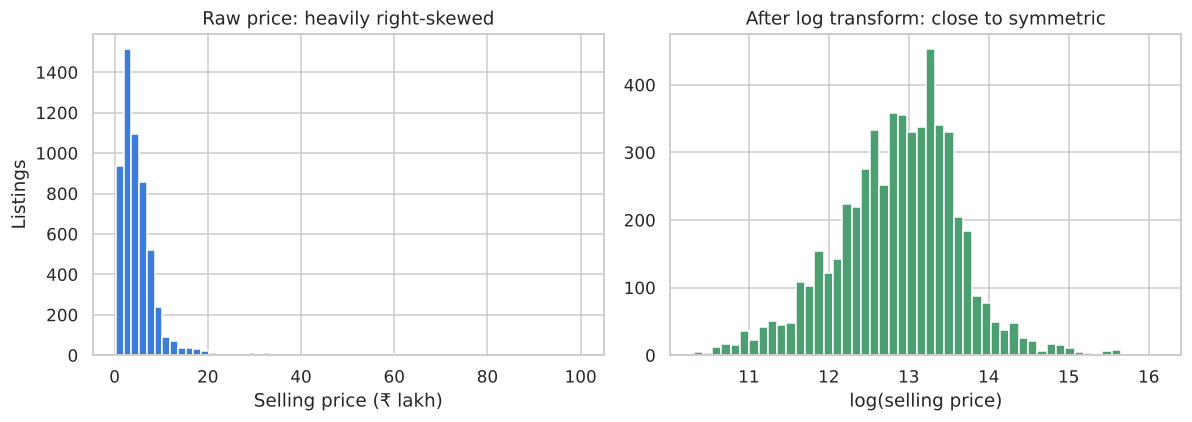

median ₹4.0 lakh | mean ₹5.2 lakh | 95th pct ₹12.0 lakh | max ₹100 lakh


In [6]:
# Plot 1: price distribution, raw vs log
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(eda["price_lakh"], bins=60, color="#3B7DD8"); ax[0].set_xlabel("Selling price (₹ lakh)"); ax[0].set_ylabel("Listings"); ax[0].set_title("Raw price: heavily right-skewed")
ax[1].hist(eda["log_price"], bins=50, color="#4C9F70"); ax[1].set_xlabel("log(selling price)"); ax[1].set_title("After log transform: close to symmetric")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig01_price_distribution.png", dpi=150, bbox_inches="tight"); plt.show()
print("median ₹%.1f lakh | mean ₹%.1f lakh | 95th pct ₹%.1f lakh | max ₹%.0f lakh" % (eda.price_lakh.median(), eda.price_lakh.mean(), eda.price_lakh.quantile(.95), eda.price_lakh.max()))

**Insight 1 — price distribution.** Prices are strongly right-skewed (skewness 5.8): the median car costs ₹4.0 lakh but the mean is ₹5.2 lakh, and a handful of luxury listings reach ₹100 lakh. After a log transform the skewness falls to −0.14 (almost symmetric). This justifies modelling log(price): errors become proportional and a few very expensive cars cannot dominate the fit.

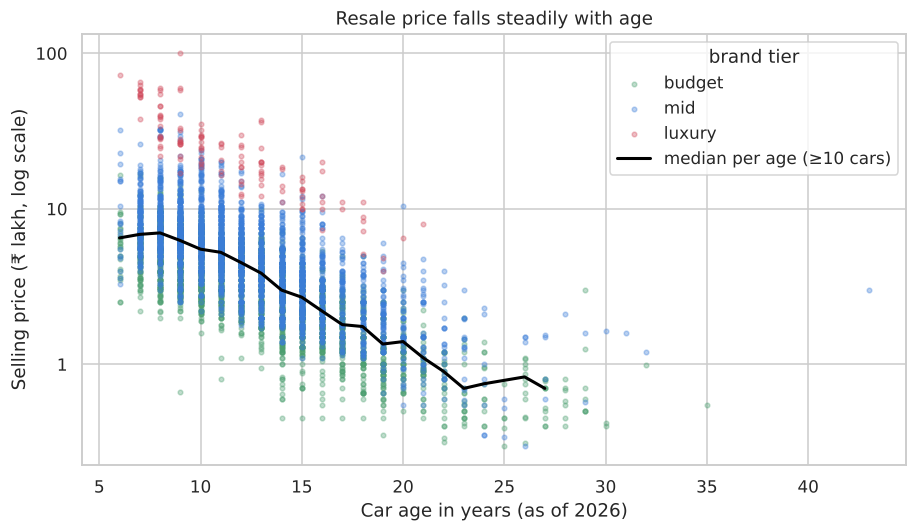

median price at age 6-7 : {6: 6.5, 7: 6.85}
median price at age 12  : 4.51 | at age 18: 1.75
Spearman corr(age, price): -0.71


In [7]:
# Plot 2: price vs age
fig, ax = plt.subplots(figsize=(8.5, 5))
for t in tier_order:
    s = eda[eda.brand_tier == t]
    ax.scatter(s["age"], s["price_lakh"], s=9, alpha=.35, color=tier_colors[t], label=t)
cnt = eda.groupby("age").size()
med = eda.groupby("age")["price_lakh"].median()[cnt >= 10]          # only ages with >=10 cars (stable medians)
ax.plot(med.index, med.values, color="black", lw=2, label="median per age (≥10 cars)")
ax.set_yscale("log"); ax.set_xlabel(f"Car age in years (as of {REFERENCE_YEAR})"); ax.set_ylabel("Selling price (₹ lakh, log scale)")
ax.set_title("Resale price falls steadily with age"); ax.legend(title="brand tier")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig02_price_vs_age.png", dpi=150, bbox_inches="tight"); plt.show()
a = eda.groupby("age")["price_lakh"].median()
print("median price at age 6-7 :", a.loc[6:7].round(2).to_dict())
print("median price at age 12  :", round(a.loc[12], 2), "| at age 18:", round(a.loc[18], 2) if 18 in a.index else None)
print("Spearman corr(age, price): %.2f" % eda[["age", "selling_price"]].corr(method="spearman").iloc[0, 1])

**Insight 2 — price vs age.** Price falls steadily with age (Spearman ρ = −0.71, the strongest single relationship in the data). The median price drops from ₹6.5 lakh at age 6 to ₹4.5 lakh at age 12 and ₹1.75 lakh at age 18 — roughly 10% of the remaining value lost every year. That is a *compounding* decline, which is why it looks like a straight line on the log axis. Luxury cars sit far above the budget/mid cloud at every age.

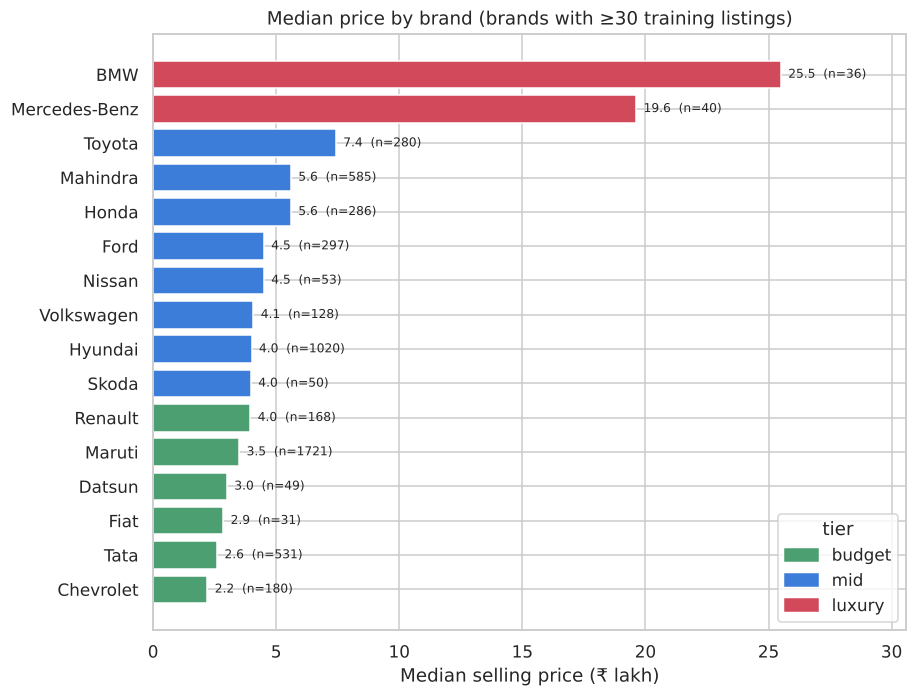

                 n  median
brand                     
BMW             36    25.5
Mercedes-Benz   40    19.6
Toyota         280     7.4
Honda          286     5.6
Mahindra       585     5.6
Share of training data from Maruti+Hyundai: 49%
Brands with <10 training rows: 13 of 31


In [8]:
# Plot 3: median price by brand
g = eda.groupby("brand").agg(n=("price_lakh", "size"), median=("price_lakh", "median"), tier=("brand_tier", "first"))
g = g[g.n >= 30].sort_values("median")
fig, ax = plt.subplots(figsize=(8.5, 6.5))
ax.barh(g.index, g["median"], color=[tier_colors[t] for t in g.tier])
for i, (m, n) in enumerate(zip(g["median"], g["n"])):
    ax.text(m + 0.3, i, f"{m:.1f}  (n={n})", va="center", fontsize=8)
ax.set_xlabel("Median selling price (₹ lakh)"); ax.set_title("Median price by brand (brands with ≥30 training listings)")
ax.set_xlim(0, g["median"].max() * 1.2)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in tier_colors.values()]
ax.legend(handles, tier_colors.keys(), title="tier", loc="lower right")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig03_price_by_brand.png", dpi=150, bbox_inches="tight"); plt.show()
print(g.sort_values("median", ascending=False).head(5)[["n", "median"]].round(1).to_string())
print("Share of training data from Maruti+Hyundai: %.0f%%" % (100 * eda.brand.isin(["Maruti", "Hyundai"]).mean()))
print("Brands with <10 training rows:", int((eda.brand.value_counts() < 10).sum()), "of", eda.brand.nunique())

**Insight 3 — price by brand.** Brand sets the price level: the median training listing is ₹25.5 lakh for BMW and ₹19.6 lakh for Mercedes-Benz, versus ₹5.6–7.4 lakh for Honda, Mahindra and Toyota and only ₹2–3 lakh for the cheapest mass-market brands such as Chevrolet and Tata. Coverage is very uneven: Maruti + Hyundai make up 49% of training rows and 13 of 31 brands have fewer than 10 rows, so estimates for rare brands rest on very few examples (one reason brand *tier* was engineered).

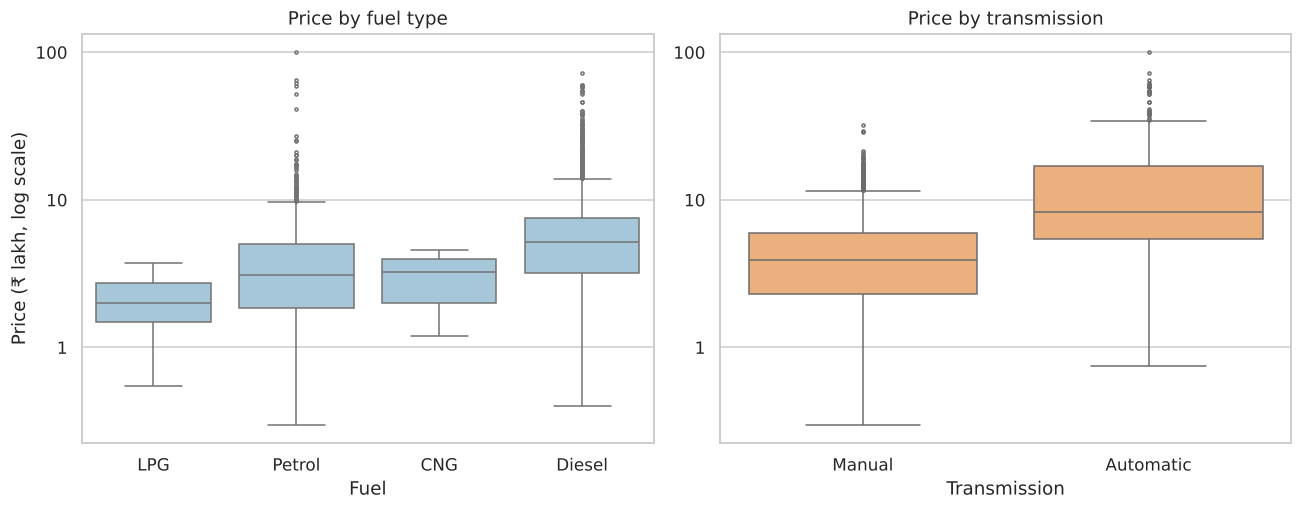

        count  median
fuel                 
CNG        42    3.22
Diesel   2995    5.20
LPG        31    2.00
Petrol   2470    3.10
              count  median
transmission               
Automatic       466     8.3
Manual         5072     3.9
Share of Automatic that is luxury: 25% vs Manual: 0%
Median age  Diesel vs Petrol: {'Diesel': 12.0, 'Petrol': 12.0}


In [9]:
# Plot 4: fuel type and transmission vs price
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
order_f = eda.groupby("fuel")["price_lakh"].median().sort_values().index
sns.boxplot(data=eda, x="fuel", y="price_lakh", order=order_f, ax=ax[0], color="#9ecae1", fliersize=2)
ax[0].set_yscale("log"); ax[0].set_xlabel("Fuel"); ax[0].set_ylabel("Price (₹ lakh, log scale)"); ax[0].set_title("Price by fuel type")
sns.boxplot(data=eda, x="transmission", y="price_lakh", ax=ax[1], color="#fdae6b", fliersize=2)
ax[1].set_yscale("log"); ax[1].set_xlabel("Transmission"); ax[1].set_ylabel(""); ax[1].set_title("Price by transmission")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig04_fuel_transmission.png", dpi=150, bbox_inches="tight"); plt.show()
print(eda.groupby("fuel")["price_lakh"].agg(["count", "median"]).round(2).to_string())
print(eda.groupby("transmission")["price_lakh"].agg(["count", "median"]).round(2).to_string())
print("Share of Automatic that is luxury: %.0f%% vs Manual: %.0f%%" % tuple(100 * (eda[eda.transmission == t].brand_tier == "luxury").mean() for t in ["Automatic", "Manual"]))
print("Median age  Diesel vs Petrol:", eda.groupby("fuel")["age"].median().round(1)[["Diesel", "Petrol"]].to_dict())

**Insight 4 — fuel and transmission.** Diesel cars have a higher median price (₹5.2 lakh) than petrol (₹3.1 lakh) even though both have the same median age (12 years), so it is not an age effect — a plausible (untested) explanation is that diesel is offered mostly on larger, higher-spec models. CNG/LPG are cheapest (₹3.2 / ₹2.0 lakh) but with only 42 and 31 cars their medians are noisy. Automatic cars cost about twice as much as manual (₹8.3 vs ₹3.9 lakh), but nearly all luxury cars are automatic (25% of automatics vs ~0% of manuals), so transmission partly acts as a proxy for segment rather than a pure effect.

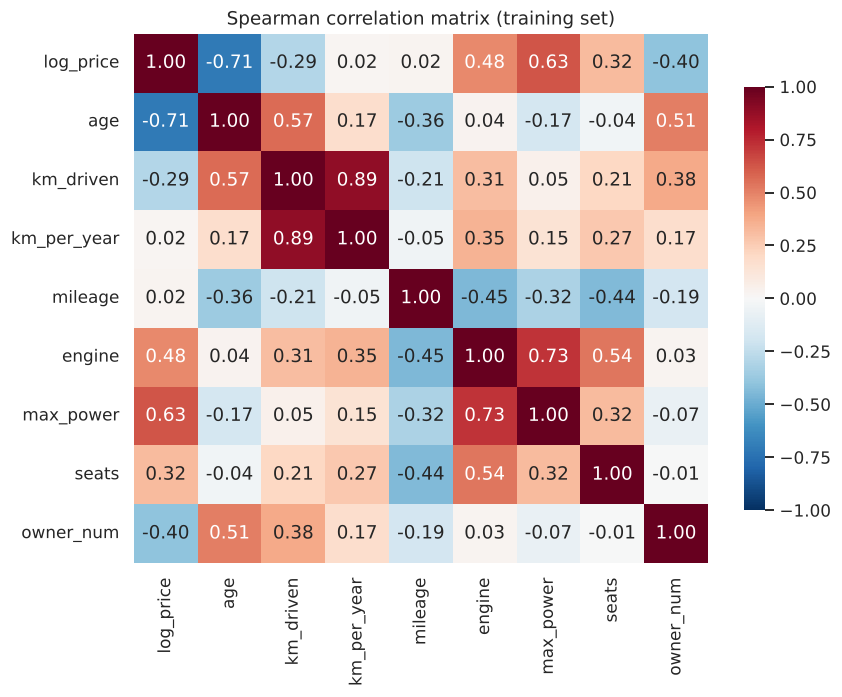

age           -0.71
owner_num     -0.40
km_driven     -0.29
km_per_year    0.02
mileage        0.02
seats          0.32
engine         0.48
max_power      0.63
corr(engine, max_power) = 0.73 | corr(age, km_driven) = 0.57


In [10]:
# Plot 5: correlation heatmap (Spearman = robust to skew/outliers)
corr_cols = ["log_price", "age", "km_driven", "km_per_year", "mileage", "engine", "max_power", "seats", "owner_num"]
corr = eda[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Spearman correlation matrix (training set)")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig05_correlation_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()
print(corr["log_price"].drop("log_price").sort_values().round(2).to_string())
print("corr(engine, max_power) = %.2f | corr(age, km_driven) = %.2f" % (corr.loc["engine", "max_power"], corr.loc["age", "km_driven"]))

**Insight 5 — correlations.** Age (ρ = −0.71) and max_power (+0.63) have the strongest links to price, followed by engine size (+0.48) and number of owners (−0.40). km_driven is only moderately negative (−0.29) because it is entangled with age (ρ = 0.57 between them), and km_per_year has almost no relationship on its own (0.02), as does mileage in kmpl (0.02). engine and max_power are strongly correlated (0.73) — overlapping information, a multicollinearity concern for linear regression but harmless for tree models.

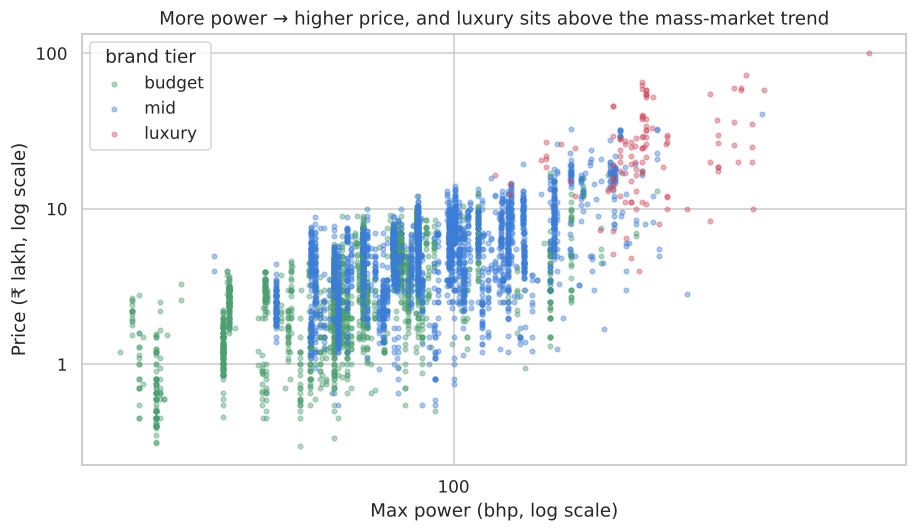

Spearman corr(max_power, price) = 0.63
Cars with 120-200 bhp, median price by tier (₹ lakh):
            count  median
brand_tier               
budget        114    4.40
luxury         86   21.99
mid           550    8.40


In [11]:
# Plot 6: engine power vs price, coloured by tier
fig, ax = plt.subplots(figsize=(8.5, 5))
for t in tier_order:
    s = eda[eda.brand_tier == t]
    ax.scatter(s["max_power"], s["price_lakh"], s=9, alpha=.4, color=tier_colors[t], label=t)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("Max power (bhp, log scale)"); ax.set_ylabel("Price (₹ lakh, log scale)")
ax.set_title("More power → higher price, and luxury sits above the mass-market trend"); ax.legend(title="brand tier")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig06_power_vs_price.png", dpi=150, bbox_inches="tight"); plt.show()
ok = eda.dropna(subset=["max_power"])
print("Spearman corr(max_power, price) = %.2f" % ok[["max_power", "selling_price"]].corr(method="spearman").iloc[0, 1])
lo = ok[(ok.max_power.between(120, 200))]
print("Cars with 120-200 bhp, median price by tier (₹ lakh):"); print(lo.groupby("brand_tier")["price_lakh"].agg(["count", "median"]).round(2).to_string())

**Insight 6 — power vs price and the role of brand.** More power means a higher price (ρ = 0.63), but power alone does not set the price: among cars with 120–200 bhp the median listing is ₹4.4 lakh for budget brands, ₹8.4 lakh for mid-range brands and ₹22.0 lakh for luxury brands (not adjusted for age). Brand/segment shifts the whole price curve upward, which is why `brand` and `brand_tier` are kept as features.

## 4. Modelling

### Why these models (plain-language justification)
| Model | Role | Why it's here |
|---|---|---|
| **Median predictor** (`DummyRegressor`) | Baseline | The "do nothing" benchmark. Any real model must beat it, otherwise it has learned nothing. |
| **Linear Regression** | Simple, interpretable model | Assumes each factor shifts price by a fixed amount. Fast, easy to explain — but can't capture interactions (e.g. "age matters more for luxury cars"). |
| **Random Forest** | Non-linear ensemble | Averages many decision trees trained on random subsets; captures interactions and thresholds automatically, robust to outliers, little tuning needed. |
| **XGBoost** | Gradient-boosted trees | Builds trees *sequentially*, each correcting the previous ones' mistakes. Usually the strongest on tabular data of this size. |

### Key design choices
- **Log-transform the target.** Price is right-skewed and effects are *multiplicative* (a car loses ~X% of its value per year, not a fixed rupee amount). Training on `log(price)` makes errors proportional and stops a few ₹50-lakh cars from dominating training. It is done inside `TransformedTargetRegressor`, so the pipeline still **outputs rupees**.
- **One Pipeline for everything:** `feature engineering → impute/scale/one-hot → model`. Preprocessing is re-fitted on each CV training fold, so no information leaks from validation/test data.
- **Tuning with 5-fold CV on the training set** (`RandomizedSearchCV`, `KFold(shuffle=True, random_state=42)`). Random search tries 12–20 random hyper-parameter combos instead of every combination: nearly as good, far cheaper.
- **Tuning metric = RMSLE** (root mean squared *log* error ≈ typical % error). A ₹50,000 error is huge on a ₹1.5 lakh car but trivial on a ₹40 lakh car; RMSLE treats them proportionally, plain RMSE would only care about expensive cars.
- **Model selection on the validation set**, then each model is **re-fitted on train+validation** with the chosen hyper-parameters and scored **once** on the untouched test set.

In [12]:
def rmsle(y_true, y_pred):
    return float(np.sqrt(np.mean((np.log1p(y_true) - np.log1p(y_pred)) ** 2)))

def evaluate(y_true, y_pred):
    return {"RMSE (₹)": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAE (₹)": float(mean_absolute_error(y_true, y_pred)),
            "R²": float(r2_score(y_true, y_pred)),
            "MAPE (%)": float(100 * mean_absolute_percentage_error(y_true, y_pred)),
            "RMSLE": rmsle(y_true, y_pred)}

rmsle_scorer = make_scorer(rmsle, greater_is_better=False)
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models, cv_scores = {}, {}

# ---- Baseline: always predict the training-set median price
models["Baseline (median)"] = cf.build_pipeline(DummyRegressor(strategy="median"), log_target=False).fit(X_train, y_train)
cv_scores["Baseline (median)"] = -cross_val_score(cf.build_pipeline(DummyRegressor(strategy="median"), log_target=False), X_train, y_train, cv=cv, scoring=rmsle_scorer).mean()
print("Baseline median price (₹):", int(y_train.median()))

# ---- Linear Regression
lr = cf.build_pipeline(LinearRegression())
cv_scores["Linear Regression"] = -cross_val_score(lr, X_train, y_train, cv=cv, scoring=rmsle_scorer).mean()
models["Linear Regression"] = lr.fit(X_train, y_train)
print("Linear Regression CV RMSLE: %.3f" % cv_scores["Linear Regression"])

Baseline median price (₹): 400000


Linear Regression CV RMSLE: 0.263


In [13]:
# ---- Random Forest (randomised search, 5-fold CV on TRAIN only)
rf_space = {"model__regressor__n_estimators": [200, 300],
            "model__regressor__max_depth": [None, 15, 25],
            "model__regressor__min_samples_leaf": [1, 2, 4],
            "model__regressor__max_features": [0.4, 0.6, 0.8, 1.0]}
rf_search = RandomizedSearchCV(cf.build_pipeline(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
                               rf_space, n_iter=12, cv=cv, scoring=rmsle_scorer,
                               random_state=RANDOM_STATE, n_jobs=1, refit=True).fit(X_train, y_train)
models["Random Forest"] = rf_search.best_estimator_
cv_scores["Random Forest"] = -rf_search.best_score_
print("RF best params:", {k.split("__")[-1]: v for k, v in rf_search.best_params_.items()}, "| CV RMSLE: %.3f" % cv_scores["Random Forest"])

RF best params: {'n_estimators': 200, 'min_samples_leaf': 2, 'max_features': 0.4, 'max_depth': 25} | CV RMSLE: 0.220


In [14]:
# ---- XGBoost (randomised search, 5-fold CV on TRAIN only)
xgb_space = {"model__regressor__n_estimators": [300, 500, 800],
             "model__regressor__learning_rate": [0.03, 0.05, 0.1],
             "model__regressor__max_depth": [3, 4, 6, 8],
             "model__regressor__min_child_weight": [1, 3, 5],
             "model__regressor__subsample": [0.7, 0.85, 1.0],
             "model__regressor__colsample_bytree": [0.6, 0.8, 1.0]}
xgb_base = XGBRegressor(random_state=RANDOM_STATE, tree_method="hist", n_jobs=-1, objective="reg:squarederror")
xgb_search = RandomizedSearchCV(cf.build_pipeline(xgb_base), xgb_space, n_iter=15, cv=cv, scoring=rmsle_scorer,
                                random_state=RANDOM_STATE, n_jobs=1, refit=True).fit(X_train, y_train)
models["XGBoost"] = xgb_search.best_estimator_
cv_scores["XGBoost"] = -xgb_search.best_score_
print("XGB best params:", {k.split("__")[-1]: v for k, v in xgb_search.best_params_.items()}, "| CV RMSLE: %.3f" % cv_scores["XGBoost"])

XGB best params: {'subsample': 0.85, 'n_estimators': 800, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.6} | CV RMSLE: 0.217


### Model comparison on the **validation** set (used to choose the winner)
All models were fitted on the 80% training set only; this table is what I use to decide which model to keep.

In [15]:
val_table = pd.DataFrame({name: evaluate(y_val, m.predict(X_val)) for name, m in models.items()}).T
val_table.insert(0, "CV RMSLE (train)", pd.Series(cv_scores))
val_table = val_table.round({"RMSE (₹)": 0, "MAE (₹)": 0, "R²": 3, "MAPE (%)": 1, "RMSLE": 3, "CV RMSLE (train)": 3})
display(val_table)
val_table.to_csv("results/validation_metrics.csv")

real_models = [m for m in models if not m.startswith("Baseline")]
best_name = val_table.loc[real_models, "RMSLE"].astype(float).idxmin()
print("Best model on validation (lowest RMSLE):", best_name)
print("Does it also win on RMSE, MAE, R² and MAPE?",
      {c: val_table.loc[real_models, c].astype(float).idxmin() if c != "R²" else val_table.loc[real_models, c].astype(float).idxmax()
       for c in ["RMSE (₹)", "MAE (₹)", "R²", "MAPE (%)"]})

,CV RMSLE (train),RMSE (₹),MAE (₹),R²,MAPE (%),RMSLE
Baseline (median),0.763,488652.0,274576.0,-0.057,81.6,0.772
Linear Regression,0.263,182795.0,99452.0,0.852,20.9,0.261
Random Forest,0.220,143274.0,76309.0,0.909,16.6,0.219
XGBoost,0.217,133337.0,74057.0,0.921,16.4,0.218


Best model on validation (lowest RMSLE): XGBoost
Does it also win on RMSE, MAE, R² and MAPE? {'RMSE (₹)': 'XGBoost', 'MAE (₹)': 'XGBoost', 'R²': 'XGBoost', 'MAPE (%)': 'XGBoost'}


**Reading the validation table.** All real models beat the baseline by a wide margin. The median-price baseline has R² ≈ −0.06 and MAPE ≈ 82%; Linear Regression reaches R² 0.85 / MAPE 20.9%, Random Forest 0.91 / 16.6% and XGBoost 0.92 / 16.4%. XGBoost is best on **every** validation metric (RMSE ₹1.33 lakh vs ₹1.43 lakh for RF; on RMSLE the margin is razor-thin, 0.218 vs 0.219) and also has the lowest cross-validated RMSLE on the training set (0.217 vs 0.220 RF and 0.263 LR). The gap between linear and tree models is large and real: non-linearity and interactions matter (e.g. depreciation differs by segment). The gap between RF and XGBoost is small. CV RMSLE (0.217) and validation RMSLE (0.218) are close, which suggests the models are not overfitting.

### Final evaluation on the held-out **test** set
Each model is re-fitted on **train + validation** (90% of data, hyper-parameters fixed from the CV search) and scored once on the test set. The saved model (§9) is exactly the winning pipeline from this step.

### Why these metrics?
- **RMSE (₹):** average error in rupees, punishes big misses (outlier-sensitive, so it mostly reflects expensive cars).
- **MAE (₹):** the "typical" rupee error — easy to explain to a buyer.
- **R²:** share of price variation explained (0 = no better than predicting the mean, 1 = perfect).
- **MAPE (%):** average *percentage* error — the most natural metric for prices, because a buyer thinks "I was off by 10%", not "off by ₹40,000" (which is trivial on a ₹40-lakh car but huge on a ₹1-lakh car). Its weakness: it exaggerates errors on very cheap cars, so I read it together with MAE.
- **RMSLE:** log-scale error (≈ % error) that I also tuned on.

Using several metrics matters here: R² and RMSE are dominated by expensive cars, MAPE and RMSLE by cheap ones. A model that is good on all of them is genuinely good.

,RMSE (₹),MAE (₹),R²,MAPE (%),RMSLE
Baseline (median),529688.0,278974.0,-0.051,80.8,0.772
Linear Regression,185391.0,97595.0,0.871,20.8,0.255
Random Forest,153497.0,76336.0,0.912,16.7,0.216
XGBoost,156309.0,74713.0,0.908,16.4,0.215


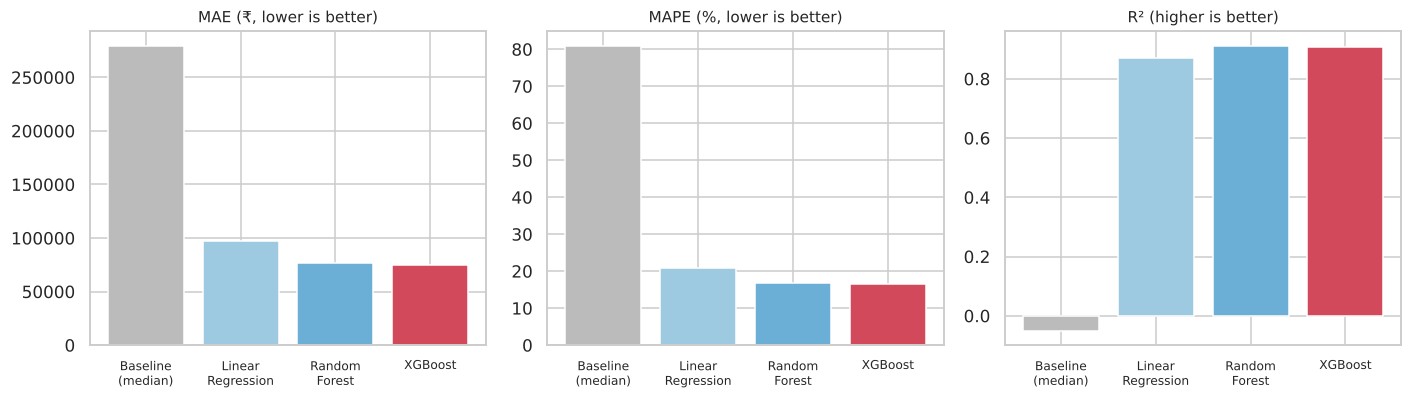

In [16]:
X_trval = pd.concat([X_train, X_val]); y_trval = pd.concat([y_train, y_val])
final = {name: clone(m).fit(X_trval, y_trval) for name, m in models.items()}
test_preds = {name: m.predict(X_test) for name, m in final.items()}
test_table = pd.DataFrame({name: evaluate(y_test, p) for name, p in test_preds.items()}).T
test_table = test_table.round({"RMSE (₹)": 0, "MAE (₹)": 0, "R²": 3, "MAPE (%)": 1, "RMSLE": 3})
display(test_table)
test_table.to_csv("results/test_metrics.csv")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
colors = ["#bbbbbb", "#9ecae1", "#6baed6", "#D1495B"]
for a, col, ttl in zip(ax, ["MAE (₹)", "MAPE (%)", "R²"], ["MAE (₹, lower is better)", "MAPE (%, lower is better)", "R² (higher is better)"]):
    a.bar(range(len(test_table)), test_table[col].astype(float), color=colors)
    a.set_xticks(range(len(test_table))); a.set_xticklabels([n.replace(" (median)", "\n(median)").replace(" ", "\n", 1) for n in test_table.index], fontsize=8)
    a.set_title(ttl, fontsize=10)
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig07_model_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

In [17]:
# How certain are we? Bootstrap the 693 test cars (1,000 resamples) -> 95% confidence intervals
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.values; pb = np.asarray(test_preds[best_name])
other = "Random Forest" if best_name != "Random Forest" else "XGBoost"; po = np.asarray(test_preds[other])
res = {"MAE": [], "MAPE": [], "R2": [], "MAE_gap": []}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    res["MAE"].append(mean_absolute_error(yt[i], pb[i])); res["MAPE"].append(100 * mean_absolute_percentage_error(yt[i], pb[i]))
    res["R2"].append(r2_score(yt[i], pb[i])); res["MAE_gap"].append(mean_absolute_error(yt[i], po[i]) - mean_absolute_error(yt[i], pb[i]))
ci = {k: np.percentile(v, [2.5, 97.5]) for k, v in res.items()}
print(f"{best_name} test MAE  95% CI: ₹{ci['MAE'][0]:,.0f} – ₹{ci['MAE'][1]:,.0f}")
print(f"{best_name} test MAPE 95% CI: {ci['MAPE'][0]:.1f}% – {ci['MAPE'][1]:.1f}%")
print(f"{best_name} test R²   95% CI: {ci['R2'][0]:.3f} – {ci['R2'][1]:.3f}")
print(f"MAE({other}) − MAE({best_name}): 95% CI ₹{ci['MAE_gap'][0]:,.0f} to ₹{ci['MAE_gap'][1]:,.0f}  (CI containing 0 => the two tree models are statistically tied)")
json.dump({k: [float(v[0]), float(v[1])] for k, v in ci.items()}, open("results/bootstrap_ci.json", "w"), indent=2)

XGBoost test MAE  95% CI: ₹65,319 – ₹85,685
XGBoost test MAPE 95% CI: 15.1% – 17.8%
XGBoost test R²   95% CI: 0.850 – 0.950
MAE(Random Forest) − MAE(XGBoost): 95% CI ₹-1,650 to ₹5,280  (CI containing 0 => the two tree models are statistically tied)


**Reading the test table.** On the untouched test set both tree models clearly beat Linear Regression and the baseline. **XGBoost: RMSE ₹1.56 lakh, MAE ≈ ₹74.7k, R² 0.908, MAPE 16.4%, RMSLE 0.215**; Random Forest: RMSE ₹1.53 lakh, MAE ≈ ₹76.3k, R² 0.912, MAPE 16.7%, RMSLE 0.216; Linear Regression: MAE ≈ ₹97.6k, R² 0.871, MAPE 20.8%; baseline: MAE ≈ ₹2.79 lakh, R² −0.05, MAPE 81%. XGBoost cuts the baseline's MAE by about 73%. Test scores are close to validation scores, so there is no sign of overfitting to the validation set. Bootstrap 95% intervals on the 693 test cars: MAE ₹65k–₹86k, MAPE 15.1–17.8%, R² 0.85–0.95. The Random Forest–XGBoost MAE gap (−₹1.7k to +₹5.3k) includes zero and the two win on different metrics (RF on RMSE/R², XGBoost on MAE/MAPE/RMSLE), so **the two tree models are statistically tied on the test set**. I selected XGBoost because it won on validation on every metric — a decision made *before* looking at the test set — and I would say honestly in the viva that either choice is defensible.

## 5. Error analysis (best model, test set)
Averages hide where a model fails. Below I look at residual patterns and break errors down by price bracket, age, brand tier and brand.

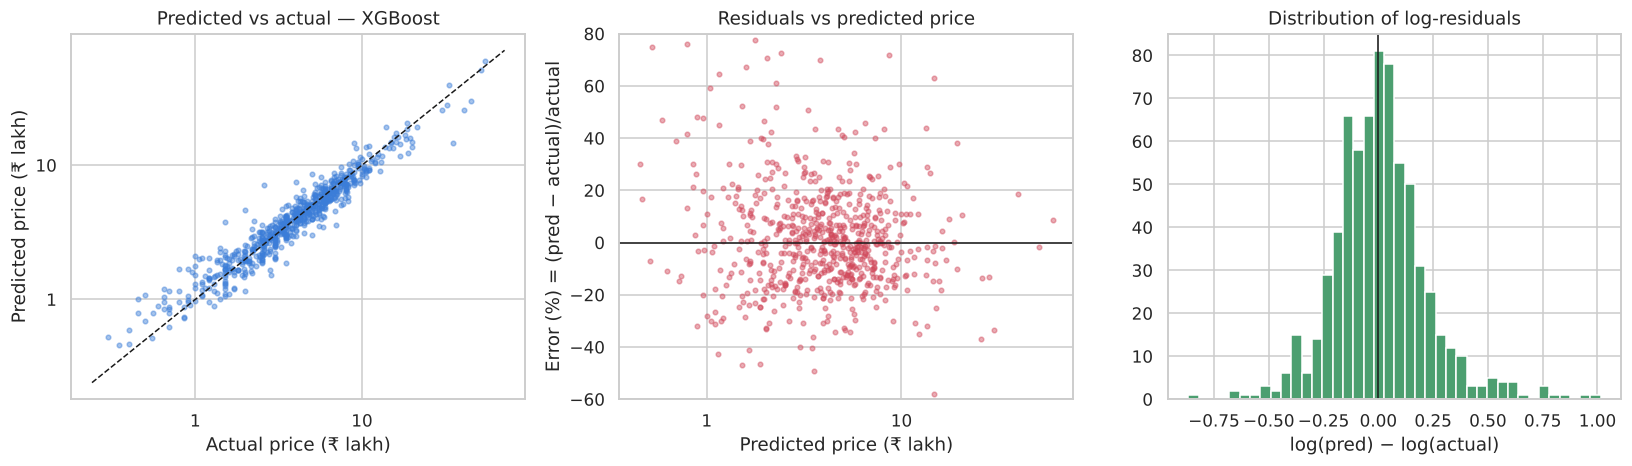

Mean log-residual: 0.009 | std: 0.215 | skew: 0.56
Share of test cars within ±10%: 42% | within ±20%: 75%


In [18]:
best_pipe = final[best_name]
pred = pd.Series(test_preds[best_name], index=X_test.index)
err = pd.DataFrame({"name": df.loc[X_test.index, "name"], "brand": X_test["brand"], "year": X_test["year"],
                    "age": REFERENCE_YEAR - X_test["year"], "actual": y_test, "pred": pred})
err["resid"] = err["pred"] - err["actual"]
err["pct_err"] = 100 * err["resid"] / err["actual"]
err["abs_pct_err"] = err["pct_err"].abs()
err["log_resid"] = np.log(err["pred"]) - np.log(err["actual"])
err["tier"] = X_test["brand"].map(cf.BRAND_TIER).fillna("mid")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))
lim = [err[["actual", "pred"]].min().min() / 1e5 * .8, err[["actual", "pred"]].max().max() / 1e5 * 1.2]
ax[0].scatter(err.actual / 1e5, err.pred / 1e5, s=9, alpha=.45, color="#3B7DD8"); ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("Actual price (₹ lakh)"); ax[0].set_ylabel("Predicted price (₹ lakh)"); ax[0].set_title(f"Predicted vs actual — {best_name}")
ax[1].scatter(err.pred / 1e5, err.pct_err, s=9, alpha=.45, color="#D1495B"); ax[1].axhline(0, color="k", lw=1)
ax[1].set_xscale("log"); ax[1].set_ylim(-60, 80); ax[1].set_xlabel("Predicted price (₹ lakh)"); ax[1].set_ylabel("Error (%) = (pred − actual)/actual"); ax[1].set_title("Residuals vs predicted price")
ax[2].hist(err.log_resid, bins=40, color="#4C9F70"); ax[2].axvline(0, color="k", lw=1); ax[2].set_xlabel("log(pred) − log(actual)"); ax[2].set_title("Distribution of log-residuals")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig08_residuals.png", dpi=150, bbox_inches="tight"); plt.show()
print("Mean log-residual: %.3f | std: %.3f | skew: %.2f" % (err.log_resid.mean(), err.log_resid.std(), err.log_resid.skew()))
print("Share of test cars within ±10%%: %.0f%% | within ±20%%: %.0f%%" % ((err.abs_pct_err <= 10).mean() * 100, (err.abs_pct_err <= 20).mean() * 100))

**Insight — residual plots.** Predicted-vs-actual points hug the diagonal from ₹0.3 lakh to ₹50 lakh+, and the mean log-residual is 0.009, so the model is essentially unbiased overall. The typical spread is about ±21% (std of log-residual 0.215): 42% of test cars are within ±10% and 75% within ±20%. Two patterns stand out: (1) errors fan out at the low-price end — cheap cars are over-predicted by large percentages (top-left of the middle panel); (2) the log-residual histogram has a longer right tail (skew 0.56): large errors are mostly *over*-predictions, i.e. cars listed for much less than the model expected.


By price bracket (₹ lakh)


,n,MAE (₹),MAPE (%),Median APE (%),Bias (%)
price_bracket,,,,,
<2.5L,186.0,35983.4,25.8,17.9,16.1
2.5–5L,245.0,48121.7,13.3,10.0,1.8
5–10L,211.0,84497.6,12.2,10.3,-3.1
10–20L,42.0,194858.2,13.6,12.4,-7.5
>20L,9.0,808890.6,21.6,13.7,-15.5



By car age (years)


,n,MAE (₹),MAPE (%),Median APE (%),Bias (%)
age_bucket,,,,,
≤8,113.0,107404.2,11.2,8.6,-0.8
9–10,152.0,77943.2,11.9,9.5,2.6
11–12,116.0,91760.3,13.4,10.9,0.5
13–15,175.0,61354.4,17.8,14.7,3.3
16+,137.0,46792.2,26.6,20.1,10.1



By brand tier


,n,MAE (₹),MAPE (%),Median APE (%),Bias (%)
tier,,,,,
budget,316.0,43131.9,15.9,11.5,4.1
mid,363.0,86376.8,16.7,11.9,3.0
luxury,14.0,485093.8,20.1,17.8,-6.0



By brand (≥15 test cars)


,n,MAE (₹),MAPE (%),Median APE (%),Bias (%)
brand,,,,,
Hyundai,140.0,52412.8,11.8,10.0,0.8
Renault,23.0,52183.4,13.2,11.8,1.5
Maruti,213.0,40632.7,14.9,10.8,3.6
Tata,56.0,48751.3,18.3,15.0,3.4
Ford,43.0,72203.6,18.4,13.4,5.4
Honda,34.0,91382.3,18.7,11.4,1.9
Mahindra,65.0,95456.3,20.2,11.8,8.0
Toyota,35.0,186875.4,23.3,18.4,3.8
Volkswagen,21.0,117889.0,25.1,14.6,3.2


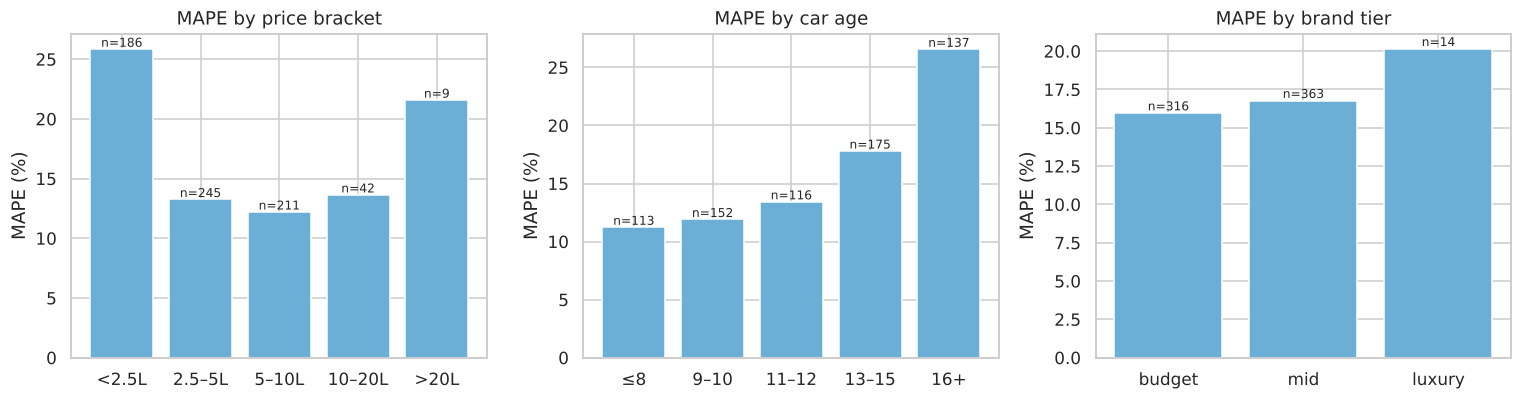

In [19]:
def breakdown(g):
    return pd.Series({"n": len(g), "MAE (₹)": g.resid.abs().mean(), "MAPE (%)": g.abs_pct_err.mean(),
                      "Median APE (%)": g.abs_pct_err.median(), "Bias (%)": g.pct_err.mean()})

err["price_bracket"] = pd.cut(err.actual, [0, 2.5e5, 5e5, 1e6, 2e6, 1e8], labels=["<2.5L", "2.5–5L", "5–10L", "10–20L", ">20L"])
err["age_bucket"] = pd.cut(err.age, [0, 8, 10, 12, 15, 40], labels=["≤8", "9–10", "11–12", "13–15", "16+"])
by_price = err.groupby("price_bracket", observed=True).apply(breakdown)
by_age = err.groupby("age_bucket", observed=True).apply(breakdown)
by_tier = err.groupby("tier").apply(breakdown).loc[["budget", "mid", "luxury"]]
brand_counts = err.brand.value_counts()
by_brand = err[err.brand.isin(brand_counts[brand_counts >= 15].index)].groupby("brand").apply(breakdown).sort_values("MAPE (%)")
for title, t in [("By price bracket (₹ lakh)", by_price), ("By car age (years)", by_age), ("By brand tier", by_tier), ("By brand (≥15 test cars)", by_brand)]:
    print("\n" + title); display(t.round(1))
by_price.round(1).to_csv("results/error_by_price.csv"); by_age.round(1).to_csv("results/error_by_age.csv")
by_tier.round(1).to_csv("results/error_by_tier.csv"); by_brand.round(1).to_csv("results/error_by_brand.csv")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, t, ttl in zip(ax, [by_price, by_age, by_tier], ["MAPE by price bracket", "MAPE by car age", "MAPE by brand tier"]):
    a.bar(t.index.astype(str), t["MAPE (%)"], color="#6baed6"); a.set_title(ttl); a.set_ylabel("MAPE (%)")
    for i, (v, n) in enumerate(zip(t["MAPE (%)"], t["n"])): a.text(i, v + .2, f"n={int(n)}", ha="center", fontsize=8)
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig09_error_breakdown.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight — where the model is right and wrong.** **By price:** percentage error is lowest for mid-priced cars (₹2.5–10 lakh: MAPE 12–13%) where most training data lies, and worst for the cheapest cars (<₹2.5 lakh: MAPE 25.8%, bias +16% — systematically over-predicted, a 'regression toward the middle'). In rupees the picture reverses (MAE ≈ ₹36k for <₹2.5 lakh vs ≈ ₹8.1 lakh for >₹20 lakh); the >₹20 lakh bracket (−15.5%) and the luxury tier (−6%, MAPE 20.1%) are under-predicted, but they have only 9 and 14 test cars, so treat those as indicative only. **By age:** error rises steadily with age — MAPE 11.2% for cars ≤8 years old vs 26.6% for 16+ years (bias +10%) — plausibly because the price of old cars depends heavily on condition, which we do not observe. **By brand:** Hyundai (11.8%) and Renault (13.2%) are predicted best; Chevrolet (25.6%, bias +14%), Volkswagen (25.1%) and Toyota (23.3%; large rupee errors, MAE ≈ ₹1.9 lakh) are hardest.

In [20]:
print("10 largest percentage errors on the test set:")
display(err.reindex(err.abs_pct_err.sort_values(ascending=False).index).head(10)[["name", "year", "actual", "pred", "pct_err"]].round(0))

10 largest percentage errors on the test set:


,name,year,actual,pred,pct_err
5745,Volkswagen Polo 1.5 TDI Comfortline,2020,260000,717391.0,176.0
1850,Mahindra Xylo E4,2009,150000,377485.0,152.0
1107,Mahindra Xylo D4 BSIII,2013,200000,464142.0,132.0
2233,Chevrolet Spark 1.0,2008,45000,99963.0,122.0
4215,Honda City 1.3 EXI,2004,50000,107743.0,115.0
4382,Toyota Qualis FS F7,2000,100000,212029.0,112.0
4271,Maruti Omni CNG,2000,80000,168253.0,110.0
2775,Honda City 2017-2020 EXi,2008,105000,199979.0,90.0
2237,Ford Fusion Plus 1.4 TDCi Diesel,2008,90000,168723.0,87.0
823,Mahindra Xylo H4,2016,400000,745910.0,86.0


**Insight — worst predictions.** All 10 of the worst predictions are *over*-predictions (+86% to +176%), mostly old/cheap cars (a 2000 Toyota Qualis, 2000 Maruti Omni, 2004 Honda City, 2008 Chevrolet Spark) or listings that look unusually low for their specs — e.g. a 2020 Volkswagen Polo 1.5 TDI listed at ₹2.6 lakh but predicted at ₹7.2 lakh, possibly a distressed sale or data-entry slip. The model cannot see condition, accident history, urgency of sale or negotiation, so a below-market listing is invisible to it. These are limits of the data rather than obvious bugs in the model.

## 6. What drives the price? (SHAP + permutation importance)
- **SHAP** explains each prediction by splitting it into a contribution from every feature. Because the model predicts *log* price, a SHAP value of +0.20 means "this feature pushes the predicted price up by about 22%" (e^0.20 ≈ 1.22) relative to an average car.
- **Permutation importance** is a model-agnostic cross-check: shuffle one raw input column and see how much the test error rises. If the pipeline relies on a feature, shuffling it hurts.
Dummy-coded columns (`brand_BMW`, `fuel_Diesel`, …) are summed back to their original feature so brand counts as one factor.

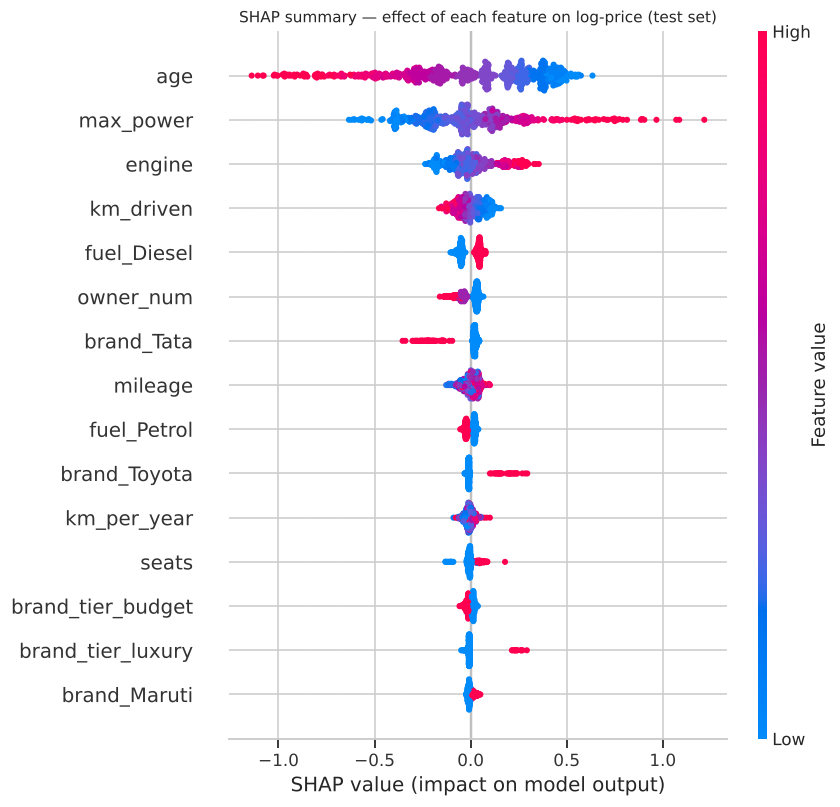

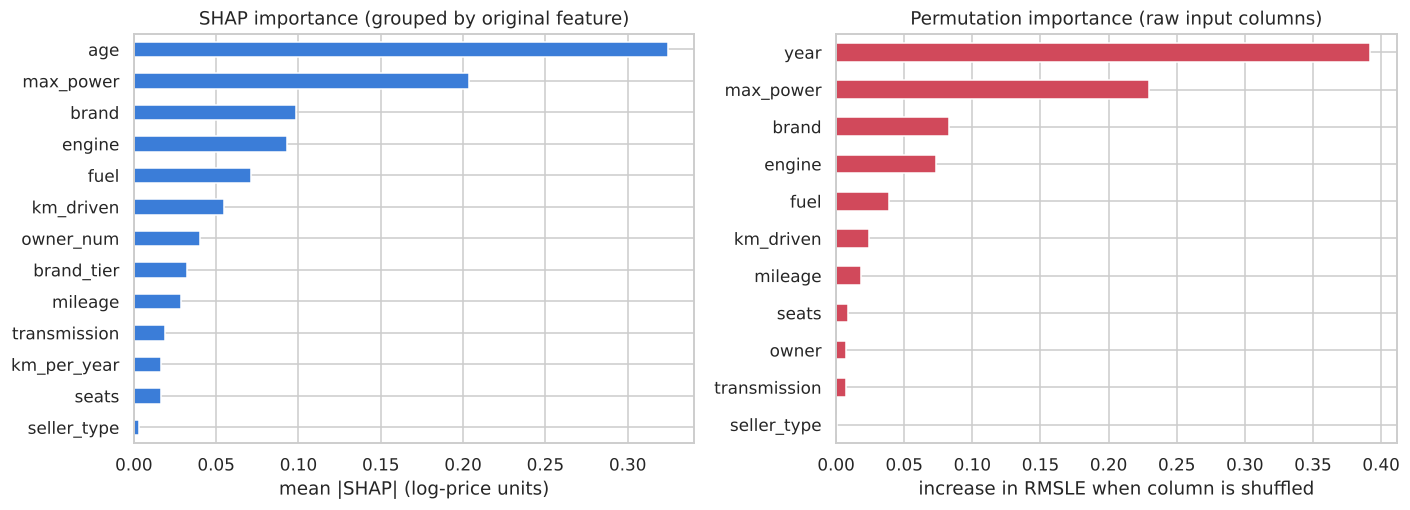

,mean_abs_shap_logprice,approx_price_swing_%
age,0.324,38.305
max_power,0.204,22.573
brand,0.098,10.326
engine,0.093,9.733
fuel,0.071,7.406
km_driven,0.055,5.619
owner_num,0.040,4.094
brand_tier,0.032,3.255
mileage,0.029,2.928
transmission,0.019,1.917


In [21]:
feat_step, prep_step = best_pipe.named_steps["features"], best_pipe.named_steps["prep"]
reg = best_pipe.named_steps["model"].regressor_
Xt = prep_step.transform(feat_step.transform(X_test))
names = [n.replace("num__", "").replace("cat__", "") for n in prep_step.get_feature_names_out()]
explainer = shap.TreeExplainer(reg)
sv = explainer.shap_values(Xt)

# (a) beeswarm of the top 15 encoded features
plt.figure(figsize=(8.5, 6))
shap.summary_plot(sv, Xt, feature_names=names, max_display=15, show=False)
plt.title("SHAP summary — effect of each feature on log-price (test set)", fontsize=10)
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig10_shap_beeswarm.png", dpi=150, bbox_inches="tight"); plt.show()

# (b) group one-hot columns back to the original feature (longest matching group name wins)
groups = NUM_COLS + CAT_COLS
def group_of(n):
    m = [g for g in groups if n == g or n.startswith(g + "_")]
    return max(m, key=len)
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=names).groupby(group_of).sum().sort_values()
shap_imp = pd.DataFrame({"mean_abs_shap_logprice": mean_abs, "approx_price_swing_%": (np.exp(mean_abs) - 1) * 100}).sort_values("mean_abs_shap_logprice", ascending=False)
shap_imp.round(3).to_csv("results/shap_importance_grouped.csv")

perm = permutation_importance(best_pipe, X_test, y_test, scoring=rmsle_scorer, n_repeats=10, random_state=RANDOM_STATE)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
perm_imp.to_csv("results/permutation_importance.csv")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
mean_abs.plot.barh(ax=ax[0], color="#3B7DD8"); ax[0].set_xlabel("mean |SHAP| (log-price units)"); ax[0].set_title("SHAP importance (grouped by original feature)")
perm_imp.plot.barh(ax=ax[1], color="#D1495B"); ax[1].set_xlabel("increase in RMSLE when column is shuffled"); ax[1].set_title("Permutation importance (raw input columns)")
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig11_feature_importance.png", dpi=150, bbox_inches="tight"); plt.show()
display(shap_imp.round(3))

**Interpretation — what drives price.** **Age is the dominant driver by a wide margin**: mean |SHAP| = 0.32 log-points, i.e. age alone typically moves a prediction by roughly ±38% relative to an average car. Next come **max_power** (0.20 → ≈ ±23%), **brand** (0.10 → ≈ ±10%), **engine size** (0.093) and **fuel** (0.071). km_driven (0.055), owner count (0.040), brand tier, mileage and transmission have small effects (each ≲ 6%); km_per_year, seats and seller type are close to negligible. Permutation importance (which works on the raw input columns) gives a consistent ordering: year (+0.39 RMSLE when shuffled) ≫ max_power (0.23) > brand (0.083) > engine (0.073) > fuel (0.039) > km_driven (0.024). In the beeswarm, older age (red) pushes price down, higher power/engine pushes it up, more km and more previous owners push it down, diesel is above petrol, the luxury tier is positive and the budget tier negative, and Toyota is positive while Tata is negative. **Caveats:** SHAP shows what the *model relies on*, not what *causes* prices; correlated features share credit (km_driven looks modest partly because age already carries most of its information; transmission looks small because power and luxury tier already capture the automatic premium).

In [22]:
# Ceteris-paribus "what-if": change ONE input for real test cars, keep everything else fixed
def whatif(label, mask, change):
    base = X_test[mask]; alt = change(base.copy())
    pct = 100 * (best_pipe.predict(alt) / best_pipe.predict(base) - 1)
    return {"scenario": label, "cars": int(mask.sum()), "median change in predicted price (%)": round(float(np.median(pct)), 1)}
allm = pd.Series(True, index=X_test.index)
rows = [
  whatif("1 year older (km unchanged)", allm, lambda d: d.assign(year=d.year - 1)),
  whatif("+20,000 km driven", allm, lambda d: d.assign(km_driven=d.km_driven + 20000)),
  whatif("+10 bhp max power", X_test.max_power.notna(), lambda d: d.assign(max_power=d.max_power + 10)),
  whatif("Petrol -> Diesel", X_test.fuel == "Petrol", lambda d: d.assign(fuel="Diesel")),
  whatif("Manual -> Automatic", X_test.transmission == "Manual", lambda d: d.assign(transmission="Automatic")),
  whatif("First -> Second owner", X_test.owner == "First Owner", lambda d: d.assign(owner="Second Owner")),
  whatif("Individual -> Dealer seller", X_test.seller_type == "Individual", lambda d: d.assign(seller_type="Dealer")),
]
whatif_table = pd.DataFrame(rows); display(whatif_table); whatif_table.to_csv("results/what_if_effects.csv", index=False)

,scenario,cars,median change in predicted price (%)
0,1 year older (km unchanged),693,-8.3
1,"+20,000 km driven",693,-2.4
2,+10 bhp max power,673,8.0
3,Petrol -> Diesel,325,16.4
4,Manual -> Automatic,632,7.6
5,First -> Second owner,428,-5.1
6,Individual -> Dealer seller,630,2.5


**What-if effects.** These what-ifs translate the model into plain numbers (one input changed, all else equal, median over real test cars): each extra year of age cuts the predicted price by about **8%**; +10 bhp adds about **8%**; petrol → diesel adds about **16%**; manual → automatic adds about **7.6%**; second instead of first owner costs about **5%**; an extra 20,000 km costs only about **2.4%** once age is held fixed; and dealer vs individual seller is worth about +2.5%. These are the model's learned associations, not guaranteed causal effects.

## 7. Secondary analysis: how does price trend with age across brands and segments?
Two views:
1. **Empirical** — median listed price by age in the training data, per tier (what the data says directly).
2. **Model-based "what-if"** — take real training cars of a segment, change only their manufacturing year (keeping their usage intensity, i.e. km/year, and all other specs fixed), and average the model's predictions. This isolates the effect of age from the fact that, say, older cars in the dataset are often cheaper models.

Annual depreciation = the compound yearly % change in predicted price over model years 2008–2020 (fitted slope of log-price vs age).

,annual change in price (%),predicted at age 6 (₹ lakh),predicted at age 18 (₹ lakh)
[tier] budget,-9.5,5.000000,1.7
[tier] mid,-9.8,7.200000,2.4
[tier] luxury,-12.8,41.299999,8.0
Maruti,-9.0,5.400000,1.9
Hyundai,-9.1,5.900000,2.1
Honda,-9.6,8.000000,2.7
Toyota,-8.0,10.000000,4.0
Mahindra,-8.6,7.900000,2.9
BMW,-12.9,46.099998,9.3
Mercedes-Benz,-12.1,33.700001,7.4


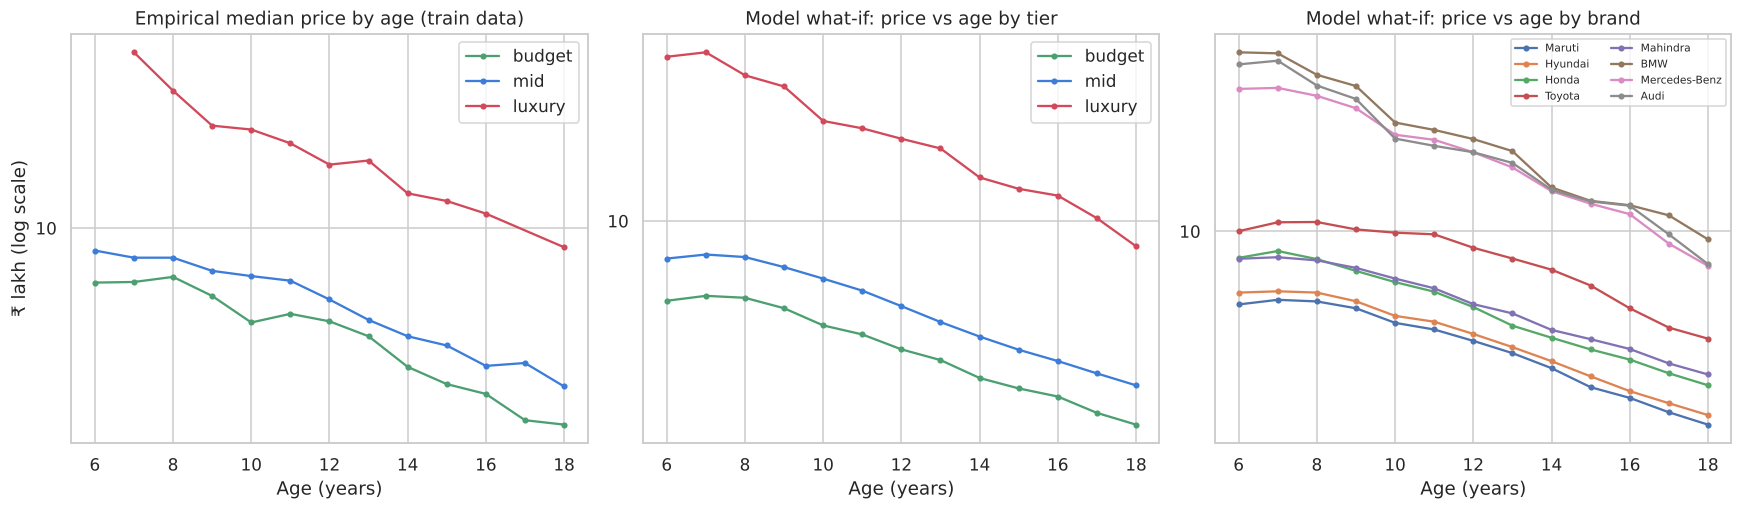

In [23]:
years = list(range(2008, 2021))
ref = pd.concat([X_trval, y_trval], axis=1)
ref["tier"] = ref["brand"].map(cf.BRAND_TIER).fillna("mid")
ref["kmpy"] = ref["km_driven"] / (REFERENCE_YEAR - ref["year"]).clip(lower=1)

def curve(rows):
    out = []
    for y in years:
        tmp = rows[RAW_FEATURES].copy()
        tmp["year"] = y
        tmp["km_driven"] = (rows["kmpy"] * (REFERENCE_YEAR - y)).round()
        out.append(np.median(best_pipe.predict(tmp)))
    return pd.Series(out, index=[REFERENCE_YEAR - y for y in years]).sort_index()   # ascending age (6 -> 18)

tier_curves = {t: curve(ref[ref.tier == t]) for t in tier_order}
brand_list = ["Maruti", "Hyundai", "Honda", "Toyota", "Mahindra", "BMW", "Mercedes-Benz", "Audi"]
brand_curves = {b: curve(ref[ref.brand == b]) for b in brand_list}

def annual_dep(s):   # compound % change per year of age
    slope = np.polyfit(s.index.values, np.log(s.values), 1)[0]
    return (np.exp(slope) - 1) * 100

dep = pd.DataFrame({"annual change in price (%)": {**{f"[tier] {t}": annual_dep(c) for t, c in tier_curves.items()},
                                                 **{b: annual_dep(c) for b, c in brand_curves.items()}},
                    "predicted at age 6 (₹ lakh)": {**{f"[tier] {t}": c.iloc[0] / 1e5 for t, c in tier_curves.items()}, **{b: c.iloc[0] / 1e5 for b, c in brand_curves.items()}},
                    "predicted at age 18 (₹ lakh)": {**{f"[tier] {t}": c.iloc[-1] / 1e5 for t, c in tier_curves.items()}, **{b: c.iloc[-1] / 1e5 for b, c in brand_curves.items()}}}).round(1)
display(dep); dep.to_csv("results/age_trend_depreciation.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
emp = eda.groupby(["age", "brand_tier"])["price_lakh"].agg(["median", "size"]).reset_index()
for t in tier_order:
    s = emp[(emp.brand_tier == t) & (emp["size"] >= 5) & (emp.age <= 18)]
    ax[0].plot(s["age"], s["median"], marker="o", ms=3, color=tier_colors[t], label=t)
ax[0].set_yscale("log"); ax[0].set_title("Empirical median price by age (train data)"); ax[0].set_xlabel("Age (years)"); ax[0].set_ylabel("₹ lakh (log scale)"); ax[0].legend()
for t in tier_order: ax[1].plot(tier_curves[t].index, tier_curves[t] / 1e5, marker="o", ms=3, color=tier_colors[t], label=t)
ax[1].set_yscale("log"); ax[1].set_title("Model what-if: price vs age by tier"); ax[1].set_xlabel("Age (years)"); ax[1].legend()
for b, c in brand_curves.items(): ax[2].plot(c.index, c / 1e5, marker="o", ms=3, label=b)
ax[2].set_yscale("log"); ax[2].set_title("Model what-if: price vs age by brand"); ax[2].set_xlabel("Age (years)"); ax[2].legend(fontsize=7, ncol=2)
fix_logs(); plt.tight_layout(); plt.savefig("figures/fig12_price_vs_age_by_segment.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight — price vs age across segments.** Cars lose value at a compounding ≈10% per year in the budget (−9.5%/yr) and mid-range (−9.8%/yr) segments, but **luxury cars depreciate faster in percentage terms (−12.8%/yr; BMW −12.9, Mercedes −12.1, Audi −13.0)**. A typical luxury car predicted at ≈₹41 lakh at age 6 falls to ≈₹8 lakh at age 18 (−81%), versus ₹5.0 → ₹1.7 lakh (−66%) for a budget car. Toyota holds value best (−8.0%/yr) followed by Mahindra (−8.6%), while Maruti, Hyundai and Honda sit at −9% to −9.6%; a possible reason is strong used-market demand for their larger MUV/SUV models, but that is not tested here. Budget and mid-range prices are nearly flat between ages 6 and 8 before declining. The empirical curves (left) and the model what-if curves (middle) have the same shape, which supports the finding.

## 8. Limitations, bias, and next steps

**Limitations**

1. **Snapshot of asking prices, and no way to extrapolate in time.** Prices are listing (asking) prices from one scrape of CarDekho (about 2020), in nominal rupees — not final sale prices, not inflation-adjusted, and blind to market swings. The data only contains model years up to 2020, so with the 2026 reference year the youngest car is 6 years old; tree models cannot extrapolate, so a 2023 car would be priced like a 2020 one. The saved model's input schema therefore limits the year to the training range.
2. **No condition or history information.** Accidents, service history, tyre/paint condition, city and negotiation are not in the data. This is the main source of residual error: MAPE rises from 11.2% (cars ≤8 years old) to 26.6% (16+ years), and the worst predictions are all unexplained low listings.
3. **Uneven coverage and bias.** Maruti + Hyundai are 49% of training rows, 13 of 31 brands have <10 rows, luxury cars are only ~2% of the data (14 in the test set) and about 90% of sellers are individuals. Luxury and rare-brand predictions are therefore far less reliable than the headline metrics, and the model tends to over-predict very cheap cars (+16%) and under-predict the most expensive (−15.5% above ₹20 lakh).
4. **Coarse features and a small test set.** Only the brand is used, not the model/variant (a Maruti can cost ₹1 lakh or ₹10 lakh); torque was dropped; ~3% of rows (224) had specs imputed with the median; 1,202 exact duplicates (15%) were removed, though a few could have been genuine repeat listings. With 693 test cars the 95% interval on MAE is wide (₹65k–₹86k), so small differences between models (RF vs XGBoost) are not meaningful.

**Next steps**

1. **Add richer features:** parse the car *model/variant* (Swift, City, Innova…) as a feature, ideally with listing date, city and condition indicators if a richer dataset is available, so that the model can separate cheap and expensive cars within the same brand and capture market drift over time. Evaluate with grouped cross-validation to confirm it generalises.
2. **Give honest uncertainty per car:** replace the single empirical ±band with quantile regression or conformal prediction so that each prediction comes with a price *range* whose coverage is guaranteed, and collect more luxury/rare-brand data (or train a separate luxury model) because that is where uncertainty is highest.

## 9. Saving the model for the Tkinter frontend
The saved object is the **entire pipeline** (feature engineering → imputation/scaling/one-hot → model → inverse log-transform). The frontend passes **raw** values only. Files written:
- `best_model.pkl` — fitted pipeline (joblib)
- `model_input_schema.json` — exact raw fields, dtypes, allowed categories, training ranges, and an empirical error band

In [24]:
joblib.dump(best_pipe, "best_model.pkl", compress=3)

ratio = (err.actual / err.pred)                      # actual/pred: multiply a prediction by this to get a plausible actual
q10, q90 = float(ratio.quantile(0.10)), float(ratio.quantile(0.90))
cat_values = {c: sorted(df[c].unique().tolist()) for c in ["fuel", "seller_type", "transmission", "owner", "brand"]}
brand_counts_all = df["brand"].value_counts()

schema = {
    "model_file": "best_model.pkl",
    "model_type": best_name,
    "target": "selling_price (INR, nominal, CarDekho listing prices; data snapshot ~2020)",
    "reference_year_for_age": REFERENCE_YEAR,
    "how_to_use": "Pass ONE row (DataFrame with these exact raw columns). Encoding/imputation/log-transform happen inside the pipeline. See predict.py.",
    "requires_module": "car_features.py must be importable when loading best_model.pkl",
    "input_fields": {
        "year":         {"dtype": "int",   "required": True,  "description": "Manufacturing year", "train_min": int(df.year.min()), "train_max": int(df.year.max())},
        "km_driven":    {"dtype": "int",   "required": True,  "description": "Odometer reading in km", "train_min": int(df.km_driven.min()), "train_max": int(df.km_driven.max())},
        "fuel":         {"dtype": "str",   "required": True,  "allowed_values": cat_values["fuel"]},
        "seller_type":  {"dtype": "str",   "required": True,  "allowed_values": cat_values["seller_type"]},
        "transmission": {"dtype": "str",   "required": True,  "allowed_values": cat_values["transmission"]},
        "owner":        {"dtype": "str",   "required": True,  "allowed_values": cat_values["owner"]},
        "mileage":      {"dtype": "float", "required": False, "description": "Fuel efficiency: kmpl (petrol/diesel) or km/kg (CNG/LPG). null -> median-imputed", "train_min": float(df.mileage.min()), "train_max": float(df.mileage.max())},
        "engine":       {"dtype": "float", "required": False, "description": "Engine displacement in CC. null -> median-imputed", "train_min": float(df.engine.min()), "train_max": float(df.engine.max())},
        "max_power":    {"dtype": "float", "required": False, "description": "Max power in bhp. null -> median-imputed", "train_min": float(df.max_power.min()), "train_max": float(df.max_power.max())},
        "seats":        {"dtype": "float", "required": False, "description": "Number of seats. null -> median-imputed", "train_min": float(df.seats.min()), "train_max": float(df.seats.max())},
        "brand":        {"dtype": "str",   "required": True,  "allowed_values": cat_values["brand"],
                         "note": "Brands with <10 training rows are pooled into an 'infrequent' bucket; unseen brands are handled gracefully (treated as unknown, tier defaults to 'mid')."},
    },
    "brand_training_counts": {k: int(v) for k, v in brand_counts_all.items()},
    "brand_tier_map": cf.BRAND_TIER,
    "error_band": {"description": "Empirical 10th/90th percentile of actual/predicted on the held-out test set -> approx. 80% range. Multiply the prediction by these factors.",
                   "low_factor": round(q10, 3), "high_factor": round(q90, 3)},
    "caveats": ["Trained on cars from model years %d-%d. Years outside this range are extrapolation and unreliable." % (df.year.min(), df.year.max()),
                "Prices are 2020-era listing (asking) prices in nominal INR, not inflation-adjusted and not final sale prices.",
                "No accident/condition/service history is available to the model."],
}
json.dump(schema, open("model_input_schema.json", "w"), indent=2)
json.dump({"input_columns": RAW_FEATURES, "example": X_test.iloc[0].replace({np.nan: None}).to_dict()}, open("results/example_input.json", "w"), indent=2, default=str)

# sanity check: reload from disk and confirm identical predictions on the test set
reloaded = joblib.load("best_model.pkl")
assert np.allclose(reloaded.predict(X_test), best_pipe.predict(X_test))
print("Saved best_model.pkl (%s). Reload check passed. 80%% error band factors: x%.2f to x%.2f" % (best_name, q10, q90))
print("Example single-car prediction (₹):", int(reloaded.predict(X_test.iloc[[0]])[0]), "| actual:", int(y_test.iloc[0]))

Saved best_model.pkl (XGBoost). Reload check passed. 80% error band factors: x0.78 to x1.25
Example single-car prediction (₹): 605415 | actual: 570000


## 10. Viva cheat-sheet (quick answers)
- **Why log-transform price?** Skewed target + multiplicative effects; makes errors proportional and models fit better. Predictions are converted back to rupees automatically.
- **Why 80/10/10?** Train learns, validation picks the model, test gives a final unbiased score. ~690 test cars is enough for a stable estimate.
- **How did you avoid leakage?** Duplicates removed before splitting; EDA on train only; imputation/scaling/encoding inside the Pipeline (re-fitted per CV fold); engineered features are stateless; brand tier from domain knowledge, not from prices.
- **Why not just use R²?** R² is dominated by expensive cars. MAPE/RMSLE show proportional accuracy, MAE shows typical rupee error.
- **Why a median baseline?** It's the best constant guess under absolute error; a model must clearly beat it to be useful.
- **Is the model causal?** No. SHAP shows what the model *relies on*, not what *causes* price changes.